# Figure 5: Research-area enrichment

Reproduce the research-area matrix from committed weighted shares, leave-one-out baselines and pointwise bootstrap intervals. Circle size shows how often an area appears among papers mentioning each package, colour marks contrasts that pass the display rule. The renderer excludes areas below the validation precision rule.

## Inputs

| Committed file | Contents | Producer |
| --- | --- | --- |
| `config/tools.yml` | Curated aliases, categories and query context | Manual registry, read by `python -m census.build.build_dataset` |
| `data/processed/tools.csv` | Package names, categories, scope and aggregate flags | `python -m census.build.build_dataset` |
| `data/processed/literature_yearly.csv` | Yearly package mention counts by source | `python -m census.build.build_dataset` |
| `data/processed/domain_enrichment.csv` | Weighted area shares, leave-one-out baselines and bootstrap intervals | `census.figures.domains.build_enrichment()` (offline function, invoked by the analysis pipeline) |
| `data/processed/domain_enrichment_control.csv` | Six microscope-control programs, each contrasted independently with the weighted analysis-only corpus; same eight columns | `census.figures.domains.build_control_enrichment(n_boot=500, seed=1)` |
| `data/processed/domain_precision_2025.csv` | Research-area validation precision and display flags | `python -m census.validation.label_round2 pooled` |

Input paths are relative to the repository root. The closing check also reads `../MANUSCRIPT/FIGURES/Figure5__domains.png` when present. The manuscript image is optional and stays outside a public clone.

## Set up offline analysis

Locate the repository in either layout, load the package registry and import the shared publication renderer. This cell makes no API requests.

In [1]:
from pathlib import Path
from io import BytesIO
from tempfile import TemporaryDirectory
import sys
import hashlib

import numpy as np
import pandas as pd
from IPython.display import Image, display
from PIL import Image as PILImage
import matplotlib.pyplot as plt

cwd = Path.cwd().resolve()
SCRIPTS_DIR = next(p for p in (cwd, *cwd.parents) if (p / 'census' / '_registry.py').is_file())
REPO_ROOT = SCRIPTS_DIR.parent
if str(SCRIPTS_DIR) not in sys.path:
    sys.path.insert(0, str(SCRIPTS_DIR))

from census._registry import build_boolean_query, load_registry
from census.figures import fig5_domains as figure
from census.figures import style as fs

reg = load_registry()
def inspect_processed(name, columns=None):
    frame = fs.load(name)
    print(f'{name}: shape={frame.shape}')
    display((frame if columns is None else frame[columns]).head())
    return frame


## Registry and query construction

The registry fixes the aliases and shared microscopy context. `build_boolean_query()` shows the alias and context clauses, package-year queries add the publication year. The analysis uses the registry's aggregate packages without microscope-control programs.

In [2]:
registry_table = pd.DataFrame([
    {'tool_id': tool.id, 'name': tool.name, 'category': tool.category, 'scope': tool.scope,
     'in_aggregate': tool.in_aggregate, 'aliases': ' | '.join(tool.aliases),
     'query': build_boolean_query(tool, reg.context_query)}
    for tool in reg.tools
])
print(f'{len(reg.tools)} packages; years {reg.year_start}-{reg.year_end}')
print(f'Shared context: {reg.context_query}')
print(f'Registry table shape: {registry_table.shape}')
display(registry_table.drop(columns='query').head(8))
display(registry_table.loc[registry_table.tool_id.isin(['imagej', 'qupath', 'napari']), ['tool_id', 'aliases', 'query']])

33 packages; years 2010-2025
Shared context: (microscopy OR microscope) AND HAS_FT:Y
Registry table shape: (33, 7)


,tool_id,name,category,scope,in_aggregate,aliases
0,jupyter,Jupyter notebooks,notebook,core,False,Jupyter | Jupyter notebook | IPython notebook
1,imagej,ImageJ / Fiji,general-platform,core,True,ImageJ | ImageJ2 | Fiji | FIJI
2,nihimage,NIH Image,general-platform,counts,False,NIH Image
3,napari,napari,general-platform,core,True,napari
4,cellprofiler,CellProfiler,general-platform,core,True,CellProfiler
5,qupath,QuPath,general-platform,core,True,QuPath
6,icy,Icy,general-platform,core,True,Icy bioimage | Icy software | de Chaumont Icy
7,ilastik,ilastik,general-platform,core,True,ilastik


,tool_id,aliases,query
1,imagej,ImageJ | ImageJ2 | Fiji | FIJI,"(""ImageJ"" OR ""ImageJ2"" OR ""Fiji"" OR ""FIJI"") AN..."
3,napari,napari,"(""napari"") AND ((microscopy OR microscope) AND..."
5,qupath,QuPath,"(""QuPath"") AND ((microscopy OR microscope) AND..."


## Read panel inputs

Load the committed data for the calculations below. The matrix shows weighted research-area shares and enrichment ratios. We recalculate ratios and apply the fold-change and pointwise interval rules to the committed estimates.

In [3]:
stored = inspect_processed('domain_enrichment.csv')
precision = inspect_processed('domain_precision_2025.csv')


domain_enrichment.csv: shape=(280, 8)


,tool_id,domain,share,baseline,ratio,lo,hi,n
0,imagej,Neuroscience,21.717161,24.342450,0.892152,0.839499,0.944855,5000
1,imagej,Cancer,23.536509,22.368584,1.052213,0.984842,1.112649,5000
2,imagej,Immunology,28.920689,30.820601,0.938356,0.893164,0.990384,5000
3,imagej,Microbiology and infection,18.997631,17.891961,1.061797,0.990289,1.131349,5000
4,imagej,Development and organoids,12.158669,13.966968,0.870530,0.800912,0.941433,5000


domain_precision_2025.csv: shape=(14, 13)


,area,agreed_v2,in_area_v2,agreed_v1,in_area_v1,agreed_em,in_area_em,precision_v2,precision_v1,precision_em,round_used,precision,shown
0,Cancer,23,15,23,15,0,0,0.6522,0.6522,NaN,v2,0.6522,True
1,Cardiovascular and renal,23,9,23,7,0,0,0.3913,0.3043,NaN,v2,0.3913,False
2,Clinical and pathology,17,11,23,13,0,0,0.6471,0.5652,NaN,v2,0.6471,True
3,Computational methods,19,17,23,17,0,0,0.8947,0.7391,NaN,v2,0.8947,True
4,Development and organoids,21,11,23,12,0,0,0.5238,0.5217,NaN,v2,0.5238,True


## Microscope-control programs

Each of the six microscope-control programs is contrasted independently with the weighted analysis-only corpus. The committed control table uses the same eight columns as the analysis-package table.

In [4]:
control_domains = inspect_processed('domain_enrichment_control.csv')
display(control_domains.loc[control_domains.tool_id.eq('zen')])

domain_enrichment_control.csv: shape=(84, 8)


,tool_id,domain,share,baseline,ratio,lo,hi,n
0,metamorph,Neuroscience,28.586701,22.292381,1.282353,1.232149,1.340544,4677
1,metamorph,Cancer,15.693821,23.280608,0.674116,0.647178,0.700840,4677
2,metamorph,Immunology,19.841779,29.336974,0.676340,0.653949,0.698014,4677
3,metamorph,Microbiology and infection,22.856532,18.755370,1.218666,1.163550,1.272256,4677
4,metamorph,Development and organoids,17.639513,12.554880,1.404992,1.325676,1.487745,4677


,tool_id,domain,share,baseline,ratio,lo,hi,n
28,zen,Neuroscience,29.305754,22.292381,1.314609,1.176468,1.453699,1000
29,zen,Cancer,17.645513,23.280608,0.757949,0.659829,0.866918,1000
30,zen,Immunology,24.353829,29.336974,0.830141,0.750424,0.927299,1000
31,zen,Microbiology and infection,25.207401,18.755370,1.344010,1.183726,1.506031,1000
32,zen,Development and organoids,17.878511,12.554880,1.424029,1.233192,1.619335,1000
33,zen,Plant biology,4.535978,4.297026,1.055609,0.784710,1.376667,1000
34,zen,Organelles and cytoskeleton,26.904421,21.806998,1.233752,1.094263,1.372796,1000
35,zen,Clinical and pathology,22.727106,29.138482,0.779969,0.692901,0.877223,1000
36,zen,Single-cell and spatial omics,8.642367,8.661562,0.997784,0.802970,1.228407,1000
37,zen,Cardiovascular and renal,12.251444,16.884368,0.725609,0.595532,0.849982,1000


## Reconstruct panel quantities

The matrix shows weighted research-area shares and enrichment ratios. We recalculate ratios and apply the fold-change and pointwise interval rules to the committed estimates.

In [5]:
enrichment = stored.copy()
enrichment['ratio_recalculated'] = enrichment.share / enrichment.baseline
enrichment['enriched'] = (enrichment.ratio >= 1.5) & (enrichment.lo > 1)
enrichment['depleted'] = (enrichment.ratio <= 1 / 1.5) & (enrichment.hi < 1)
assert np.allclose(enrichment.ratio, enrichment.ratio_recalculated, rtol=1e-10, atol=1e-12, equal_nan=True)
examples = enrichment.loc[
    ((enrichment.tool_id.eq('qupath')) & enrichment.domain.eq('Clinical and pathology')) |
    ((enrichment.tool_id.eq('napari')) & enrichment.domain.eq('Electron microscopy')) |
    ((enrichment.tool_id.eq('cellprofiler')) & enrichment.domain.eq('Computational methods')),
    ['tool_id', 'domain', 'share', 'baseline', 'ratio', 'lo', 'hi', 'enriched', 'depleted', 'n']
]
display(examples)
print(f'Stored contrasts: {enrichment.shape[0]}; display-rule hits: {int((enrichment.enriched | enrichment.depleted).sum())}.')
print('Intervals are pointwise and have no multiple-comparison adjustment.')

,tool_id,domain,share,baseline,ratio,lo,hi,enriched,depleted,n
35,qupath,Clinical and pathology,51.781060,28.727317,1.802503,1.737842,1.870264,True,False,4604
55,cellprofiler,Computational methods,15.477855,4.989553,3.102052,2.848685,3.367243,True,False,4290
221,napari,Electron microscopy,11.963190,5.352249,2.235171,2.057714,2.446945,True,False,652


Stored contrasts: 280; display-rule hits: 144.
Intervals are pointwise and have no multiple-comparison adjustment.


## Rebuilding from scratch

All default cells run offline from the committed inputs above. Source collectors need network access when their raw API caches are absent. `python -m census.build.build_dataset` collects counts and snapshots, the specialised producer modules listed under Inputs rebuild their own derived tables. Snapshots retain their original collection date.

To restore sampled titles and abstracts, run `python release/refetch_identifiers.py` with network access. The refetched corpus supports vocabulary classification and research-area calculations. A public clone omits that corpus and the raw response caches. These notebooks display derived data and never fetch records during execution.

After refetching, `census.figures.domains.build_enrichment(n_boot=500, seed=1)` rebuilds analysis-package area shares and intervals; `census.figures.domains.build_control_enrichment(n_boot=500, seed=1)` builds the six independent microscope-control contrasts against the weighted analysis-only corpus. The notebook reads `domain_enrichment.csv` and `domain_enrichment_control.csv` and does not load or display sampled text.

## Render all panels

Build `Figure5__domains` with the shared 300 dpi publication style. Save PNG, PDF and SVG in a temporary directory and retain the full-size PNG pixels for the closing check. Display a scaled preview.

wrote Figure5__domains.png/.pdf/.svg
Figure5__domains: 1942 x 1926 pixels


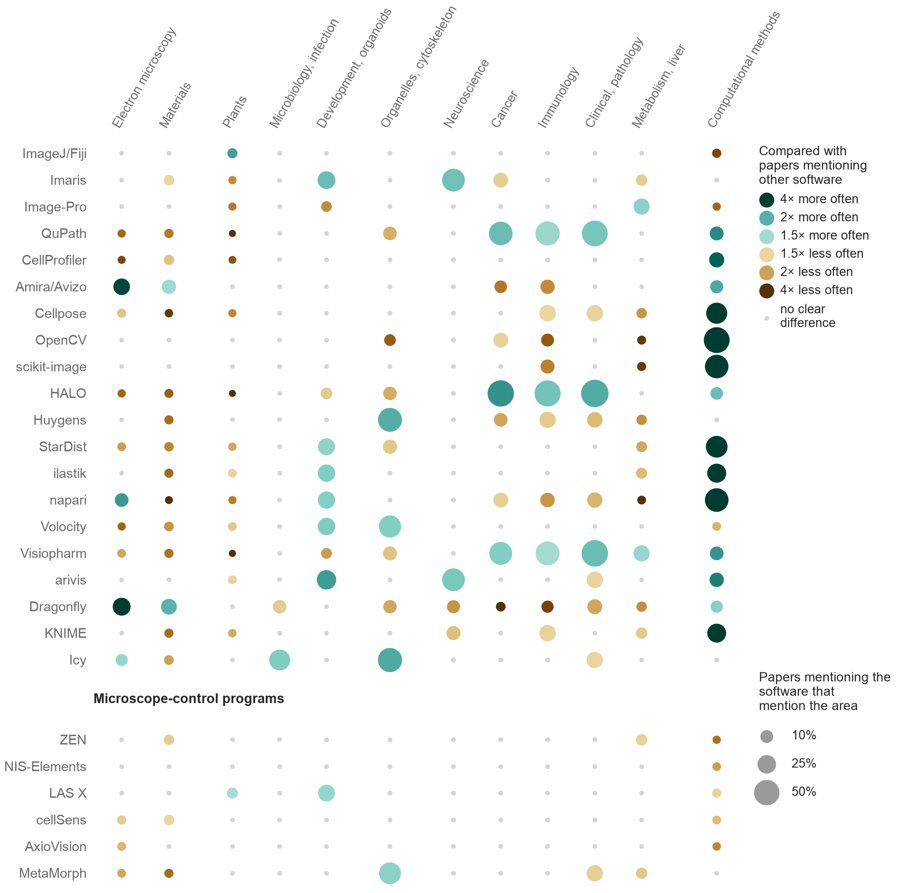

In [6]:
OUTPUT_STEM = 'Figure5__domains'
fig = figure.build_figure()
with TemporaryDirectory(prefix='notebook-render-') as output_dir:
    fs.save(fig, OUTPUT_STEM, out_dir=output_dir)
    png_bytes = (Path(output_dir) / (OUTPUT_STEM + '.png')).read_bytes()
rendered_pixels = np.asarray(PILImage.open(BytesIO(png_bytes)).convert('RGBA'))
print(f'{OUTPUT_STEM}: {rendered_pixels.shape[1]} x {rendered_pixels.shape[0]} pixels')
preview = PILImage.open(BytesIO(png_bytes))
preview.thumbnail((900, 900))
preview_bytes = BytesIO()
preview.save(preview_bytes, format='PNG')
display(Image(data=preview_bytes.getvalue(), width=min(640, preview.width)))
plt.close('all')


## Check against the manuscript

Assert exact pixel equality, including image dimensions and every panel, when the manuscript PNG exists. A public clone prints a skip note for that comparison and still checks that rendering produced pixels. The pixel hash supports comparisons across runs.

In [7]:
assert rendered_pixels.size > 0
reference = REPO_ROOT / 'MANUSCRIPT' / 'FIGURES' / (OUTPUT_STEM + '.png')
if reference.is_file():
    expected_pixels = np.asarray(PILImage.open(reference).convert('RGBA'))
    assert rendered_pixels.shape == expected_pixels.shape, 'Manuscript image dimensions differ'
    np.testing.assert_array_equal(rendered_pixels, expected_pixels)
    print(f'{OUTPUT_STEM}: identical to manuscript PNG (all pixels, all panels)')
else:
    print(f'{OUTPUT_STEM}: manuscript comparison skipped; manuscript PNG is absent in this clone')
print('Rendered pixel SHA-256:', hashlib.sha256(rendered_pixels.tobytes()).hexdigest())


Figure5__domains: manuscript comparison skipped; manuscript PNG is absent in this clone
Rendered pixel SHA-256: 4ac5fc358e92d6e8929ea49c5dc13ca4e711779f6f30d10cd458ca18b502ffa1
